---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 17 (DerbyCounty)

- Juan Oloando Simanungkalit (13524032) - juanoloando.s@gmail.com
- Nashiruddin Akram (13524090) - akrambaasir@gmail.com
- Reinsen Silitonga (13524093) - reinsilitonga12@gmail.com
- Arghawisesa Dwinanda Arham (13524100) - arghaku.argha@gmail.com
- Manuel Thimoty Silalahi (13524102) - manuelsilalahi06@gmail.com

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Penyelenggara penginapan ingin memprediksi apakah sebuah pemesanan akan dibatalkan (`is_canceled`) dari data pemesanan seperti lead time, jumlah malam, harga, kanal pemesanan, dan permintaan khusus.

## Aim

Membangun model klasifikasi biner from scratch yang memaksimalkan Macro F1 pada data test Kaggle, dengan pipeline yang reproducible.

## Metric

Macro F1 = rata-rata F1 kelas 0 dan F1 kelas 1. Kedua kelas berbobot sama, jadi model tidak cukup hanya bagus di kelas mayoritas.

## Dataset

`train.csv` berisi 27.373 baris dengan 17 fitur dan label, `test.csv` berisi 6.844 baris tanpa label. Ada missing value, duplikat, dan nilai tidak valid.

## Approach

Preprocessing bersama (dedupe, data error jadi missing, clipping, fitur turunan, imputasi median, robust scaling, bobot fitur, onehot) dipakai semua model. Model terbaik adalah KNN from scratch (k = 17, Minkowski p = 1.5, bobot 1/d²) yang digabung dengan vote booking kembar.

Notebook ini adalah hasil tuning lanjutan dari versi dasar. Preprocessing dan fitur tidak diubah. Yang disesuaikan hanya vote booking kembar dan bobot satu fitur:

- kolom `room_category` dilepas dari syarat kembar (`twin_soft`)
- bobot vote kembar naik seiring jumlah kembar, `alpha x n / (n + c0)`
- probabilitas dirata-ratakan dengan kembar lain di data yang sama (`TWIN_BETA`), hanya memakai fitur tanpa label
- bobot `booking_index` 0.5, toleransi harga 0.05, `alpha` 0.7, dan threshold 0.49

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

## Import Libraries

Every import of the notebook is kept in this cell.

In [ ]:
import hashlib
import os
import pickle
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier

# semua path relatif terhadap root repo, notebook ini bisa dijalankan dari folder mana pun di dalam repo
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'train.csv').exists()), None)
if ROOT is not None:
    os.chdir(ROOT)
print('working directory:', Path.cwd())

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED       = 5
    ID_COLUMN  = 'id'
    TARGET     = 'is_canceled'
    TEST_SIZE  = 0.2
    N_FOLDS    = 5

    # preprocessing
    CLIP_QUANTILE   = 0.005
    ONEHOT_VALUE    = 0.75
    FEATURE_WEIGHTS = {'days_before_arrival': 2.0, 'special_requests': 2.0, 'needs_parking': 0.5,
                       'weekday_nights': 0.5, 'num_adults': 0.25, 'booking_index': 0.5}

    # KNN
    K = 17
    P = 1.5

    # booking kembar
    TWIN_LEAD  = 10      # selisih lead time maksimum (hari)
    TWIN_DAY   = 2       # selisih tanggal datang maksimum (hari)
    TWIN_PRICE = 0.05    # selisih harga maksimum (relatif)
    TWIN_ALPHA = 0.7     # bobot vote kembar
    TWIN_MIN   = 2       # jumlah kembar minimum
    TWIN_C0    = 1.0     # bobot vote kembar = alpha x n / (n + c0), n = jumlah kembar
    TWIN_BETA  = 0.4     # bobot rata-rata dengan kembar lain di data yang sama
    THRESHOLD  = 0.49

    MODEL_PATH = 'output/models/knn_twin_adaptive_smoothing.pkl'
    SUB_PATH   = 'output/submissions/submission_knn_twin_adaptive_smoothing.csv'

CFG = Settings()

Penjelasan isi `Settings`:

| Nama | Nilai | Arti |
|---|---|---|
| `SEED` | 5 | seed split holdout dan k-fold, sama dengan submisi terbaik |
| `TEST_SIZE`, `N_FOLDS` | 0.2, 5 | 20% data latih untuk holdout, 5 fold untuk OOF |
| `CLIP_QUANTILE` | 0.005 | outlier dipotong ke persentil 0.5% dan 99.5% |
| `ONEHOT_VALUE` | 0.75 | nilai kolom onehot, supaya beda kategori tidak terlalu dominan di jarak |
| `FEATURE_WEIGHTS` | dict | pengali tiap fitur setelah scaling, hasil coordinate search. `booking_index` ditambah dengan bobot 0.5 |
| `K`, `P` | 17, 1.5 | jumlah tetangga dan orde jarak Minkowski |
| `TWIN_LEAD`, `TWIN_DAY`, `TWIN_PRICE`, `TWIN_ALPHA`, `TWIN_MIN` | 10, 2, 0.05, 0.7, 2 | toleransi lead (hari), tanggal datang (hari), harga (relatif), bobot vote kembar, jumlah kembar minimum |
| `TWIN_C0` | 1.0 | bobot vote kembar menjadi `alpha x n / (n + c0)`, jadi makin banyak kembar makin dipercaya. Nilai 0 mengembalikan `alpha` tetap |
| `TWIN_BETA` | 0.4 | seberapa jauh probabilitas dirata-ratakan dengan kembar lain di data yang sama. Nilai 0 mematikan langkah ini |
| `THRESHOLD` | 0.49 | batas probabilitas kelas batal yang memaksimalkan Macro F1 |

## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [ ]:
# data lokal ada di folder data/, di Kaggle ada di /kaggle/input
KAGGLE_DIR = Path('/kaggle/input/competitions/T2-IF3170-2026-2027')
DATA_DIR = KAGGLE_DIR if KAGGLE_DIR.exists() else Path('data')

train_df = pd.read_csv(DATA_DIR / 'train.csv', dtype={CFG.ID_COLUMN: str})
test_df  = pd.read_csv(DATA_DIR / 'test.csv', dtype={CFG.ID_COLUMN: str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
def types(df):
    kinds = ['numeric' if pd.api.types.is_numeric_dtype(df[column]) else 'categorical' for column in df]
    return pd.DataFrame({'dtype': df.dtypes.astype(str), 'kind': kinds, 'unique': df.nunique()})

In [7]:
types(train_df)

,dtype,kind,unique
id,str,categorical,27373
num_adults,float64,numeric,5
num_children,float64,numeric,6
weekend_nights,int64,numeric,8
weekday_nights,int64,numeric,18
meal_package,str,categorical,4
needs_parking,float64,numeric,2
room_category,str,categorical,7
days_before_arrival,float64,numeric,407
arrival_year,int64,numeric,2


In [8]:
train_df.describe()

,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


Arti tiap kolom:

| Kolom | Arti |
|---|---|
| `num_adults`, `num_children` | jumlah tamu dewasa dan anak |
| `weekend_nights`, `weekday_nights` | jumlah malam akhir pekan dan hari kerja |
| `meal_package` | paket makan (Room Only, Breakfast, Half Board, Full Board) |
| `needs_parking` | butuh tempat parkir (0/1) |
| `room_category` | tipe kamar (Type A sampai G) |
| `days_before_arrival` | lead time, jarak hari antara pemesanan dan kedatangan |
| `arrival_year`, `arrival_month`, `arrival_day` | tanggal kedatangan |
| `booking_channel` | kanal pemesanan (Online Travel Agent, Offline Agent, Corporate, Complimentary, Airline) |
| `is_returning_guest` | tamu yang pernah menginap (0/1) |
| `prior_cancellations`, `prior_completed_bookings` | riwayat pembatalan dan pemesanan selesai |
| `nightly_rate_idr` | harga per malam dalam rupiah |
| `special_requests` | jumlah permintaan khusus |
| `is_canceled` | target, 1 kalau pemesanan dibatalkan |

#### Insights

- Data berisi 27.373 baris, 13 kolom numerik dan 3 kolom kategorikal (`meal_package`, `room_category`, `booking_channel`).
- Lead time sangat menceng ke kanan: median 58 hari, tetapi maksimum 448 hari.
- Harga per malam bermedian sekitar Rp1,64 juta dengan maksimum Rp9,17 juta, dan ada 413 baris berharga 0.
- Kedatangan hanya di tahun 2023 (4.924 baris) dan 2024 (22.449 baris).
- Rentang nilai antarkolom sangat berbeda (harga jutaan, jumlah malam satuan), jadi model berbasis jarak wajib memakai scaling.

## Explore Data

This part covers distributions and relationships between attributes.

In [9]:
def target_rate(df, columns, bins=None):
    figure, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        values = pd.qcut(df[column], bins[column], duplicates='drop') if bins and column in bins else df[column]
        df.groupby(values, observed=True)[CFG.TARGET].mean().plot.bar(ax=axis)
        axis.set_title(column)
        axis.set_ylabel(f'rate {CFG.TARGET}')
    plt.tight_layout()
    plt.show()

is_canceled
0    0.672
1    0.328
Name: proportion, dtype: float64


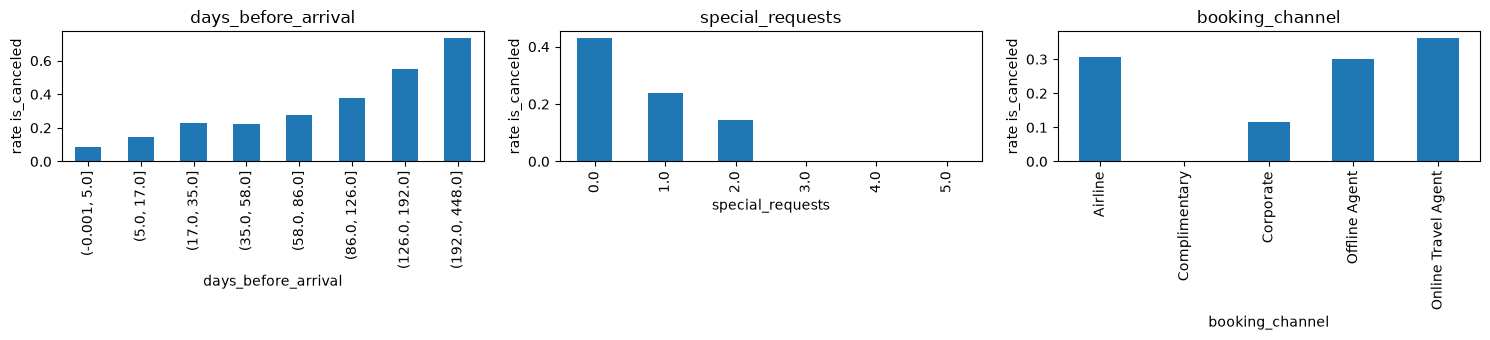

In [10]:
print(train_df[CFG.TARGET].value_counts(normalize=True).round(3))
target_rate(train_df, ['days_before_arrival', 'special_requests', 'booking_channel'], bins={'days_before_arrival': 8})

#### Insights

- Kelas tidak seimbang ringan, sekitar 33% batal. Macro F1 memberi bobot sama ke dua kelas, jadi threshold perlu ditentukan, bukan selalu 0.5.
- Lead time (`days_before_arrival`) dan `special_requests` paling kuat memisahkan kelas: booking jauh hari makin sering batal, tamu dengan permintaan khusus jarang batal. Dua fitur ini nanti diberi bobot 2 di jarak KNN.

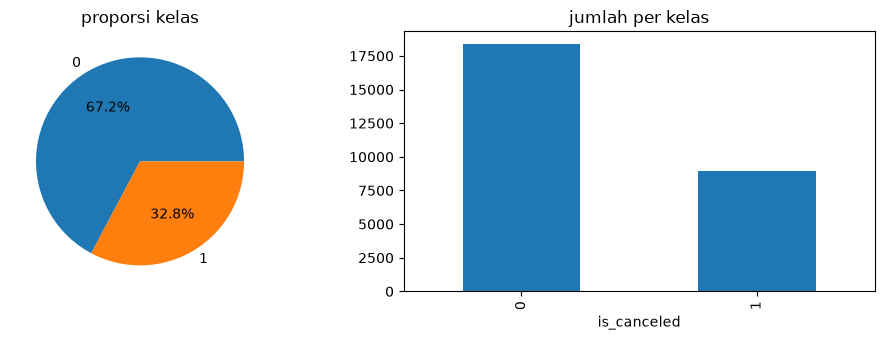

In [11]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
train_df[CFG.TARGET].value_counts().plot.pie(ax=axes[0], autopct='%.1f%%', ylabel='', title='proporsi kelas')
train_df[CFG.TARGET].value_counts().plot.bar(ax=axes[1], title='jumlah per kelas')
plt.tight_layout()
plt.show()

Distribusi fitur numerik dipisah per kelas. `density=True` supaya dua kelas yang jumlahnya beda tetap bisa dibandingkan.

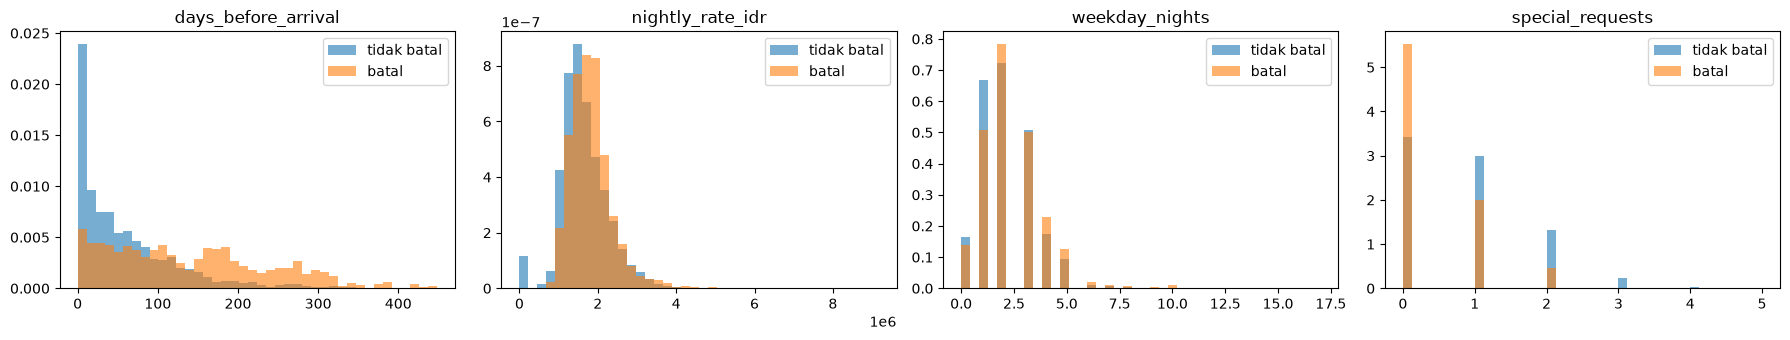

In [12]:
def histogram_by_target(df, columns, bins=40):
    figure, axes = plt.subplots(1, len(columns), figsize=(4.5 * len(columns), 3.5))
    for axis, column in zip(axes, columns):
        edges = np.histogram_bin_edges(df[column].dropna(), bins=bins)
        for label, name in [(0, 'tidak batal'), (1, 'batal')]:
            axis.hist(df.loc[df[CFG.TARGET] == label, column].dropna(), bins=edges, alpha=0.6, density=True, label=name)
        axis.set_title(column)
        axis.legend()
    plt.tight_layout()
    plt.show()

histogram_by_target(train_df, ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'special_requests'])

#### Insights

- Distribusi lead time kelas batal jauh lebih ke kanan. Rasio batal naik dari 8,8% (lead 0 sampai 5 hari) menjadi 73,8% (lead di atas 192 hari).
- Rasio batal naik seiring harga, dari 20,6% di kuintil termurah ke 44,5% di kuintil keempat, lalu turun sedikit di kuintil termahal (36,1%).
- Menginap lebih dari 10 malam punya rasio batal 68,7%, jauh di atas rata-rata.
- Tamu tanpa permintaan khusus batal 43,2%, dengan 1 permintaan 23,8%, dan dengan 3 atau lebih hampir tidak pernah batal.

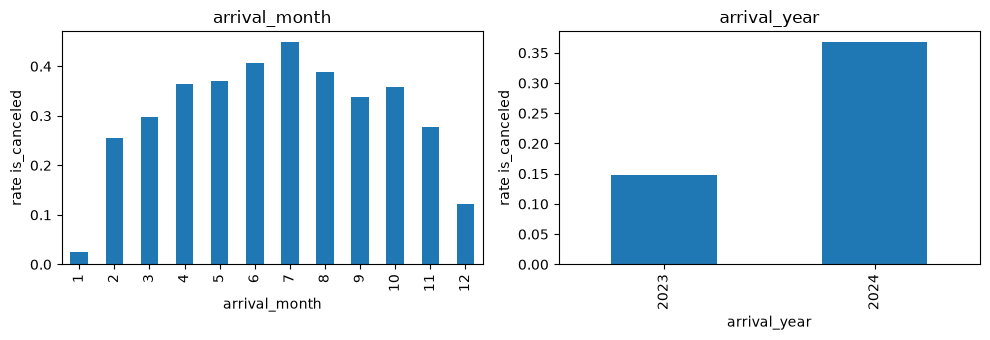

In [13]:
target_rate(train_df, ['arrival_month', 'arrival_year'])

#### Insights

- Ada pola musiman kuat: rasio batal terendah di Januari (2,6%) dan Desember (12,1%), tertinggi di Juli (44,8%).
- Korelasi linear `arrival_month` dengan target hampir 0 (-0,016) karena polanya naik lalu turun. Pola melingkar ini ditangkap oleh `month_cos`, yang membuat Desember dan Januari berdekatan.
- Tahun 2023 hanya 14,7% batal, sedangkan 2024 36,7%. `arrival_year` tidak dipakai langsung karena hanya 2 nilai dan sebagian besar efeknya sudah tertangkap lewat `booking_index`.

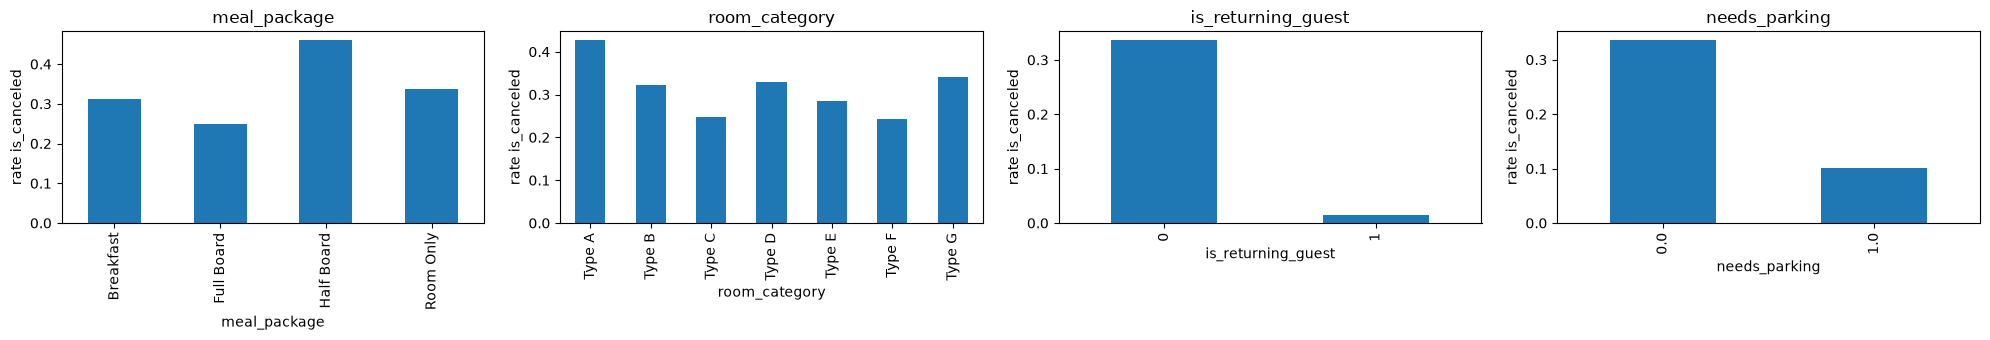

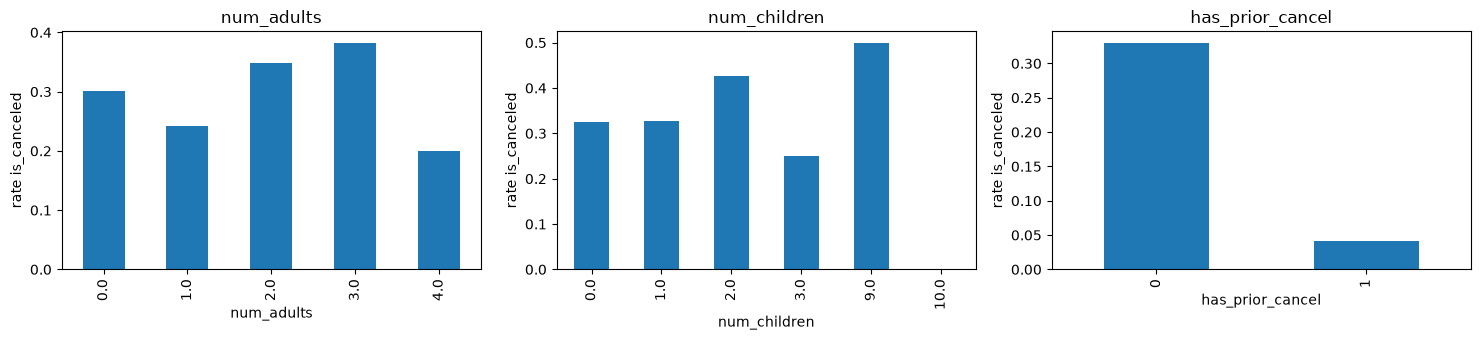

In [14]:
target_rate(train_df, ['meal_package', 'room_category', 'is_returning_guest', 'needs_parking'])
target_rate(train_df.assign(has_prior_cancel=(train_df['prior_cancellations'] > 0).astype(int)),
            ['num_adults', 'num_children', 'has_prior_cancel'])

#### Insights

- Kanal pemesanan sangat berpengaruh: Complimentary 0%, Corporate 11,5%, Offline Agent 30,2%, Online Travel Agent 36,4%.
- Tamu yang pernah menginap hampir tidak pernah batal (1,5% dibanding 33,6%). Tamu yang butuh parkir juga jarang batal (10,1% dibanding 33,5%).
- Paket Half Board paling sering batal (45,9%), sedangkan Full Board hanya 4 baris sehingga tidak bisa disimpulkan.
- Tamu dengan riwayat pembatalan justru jarang batal lagi, tetapi jumlahnya sangat sedikit (sekitar 1%).
- Beberapa kategori sangat jarang (Full Board 4 baris, Type E 7 baris, num_children 9 dan 10). Untuk KNN ini tidak masalah karena kategori jarang hanya menambah jarak.

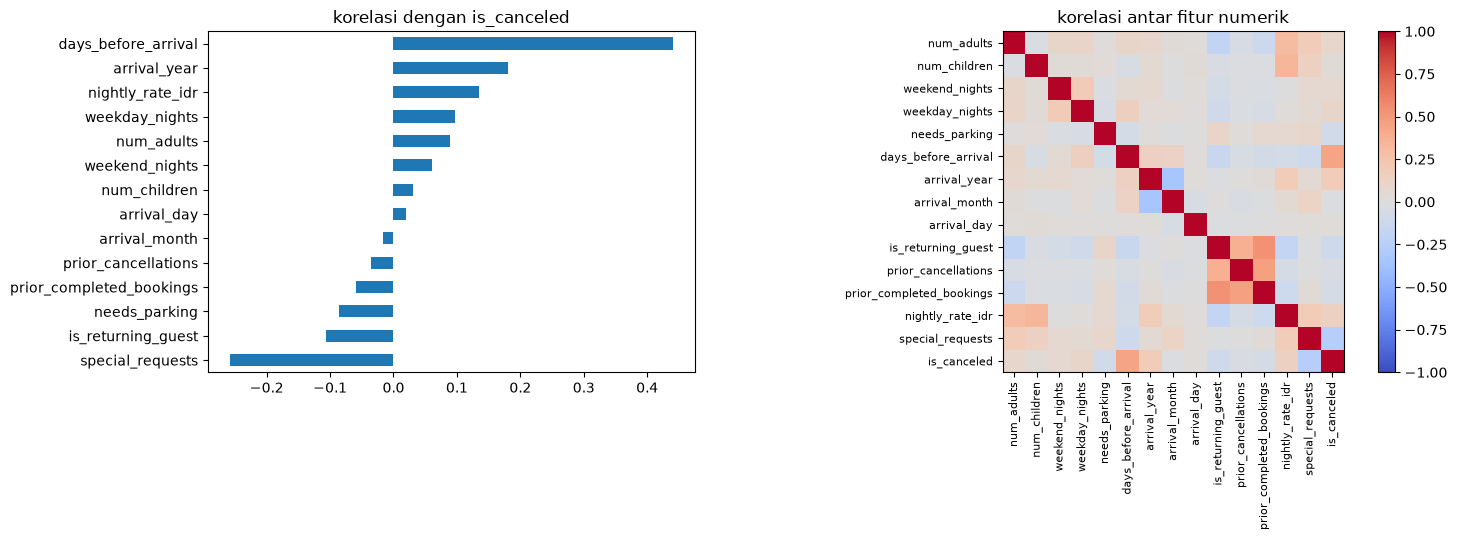

In [15]:
corr = train_df.select_dtypes('number').corr()
figure, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1, 1.4]})
corr[CFG.TARGET].drop(CFG.TARGET).sort_values().plot.barh(ax=axes[0], title='korelasi dengan is_canceled')
image = axes[1].imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
axes[1].set_yticks(range(len(corr)), corr.columns, fontsize=8)
axes[1].set_title('korelasi antar fitur numerik')
figure.colorbar(image, ax=axes[1])
plt.tight_layout()
plt.show()

#### Insights

- Korelasi terkuat dengan target: lead time (0,44), special_requests (-0,26), arrival_year (0,18), nightly_rate_idr (0,13), is_returning_guest (-0,11).
- Korelasi antarfitur rendah. Pasangan tertinggi hanya is_returning_guest dengan prior_completed_bookings (0,53), jadi tidak ada fitur yang benar-benar duplikat.
- Korelasi hanya menangkap hubungan linear. Bulan kedatangan berkorelasi hampir 0 tetapi polanya kuat (grafik musiman di atas), jadi seleksi fitur tidak boleh hanya berdasarkan korelasi.

### Booking kembar dan noise

Dataset ini berasal dari dataset publik yang diberi noise oleh penyelenggara. Untuk melihat kolom mana yang diberi noise, dicari pasangan booking yang identik di semua kolom (kecuali lead time dan tanggal datang), lalu dibandingkan selisih lead time dan tanggal datangnya.

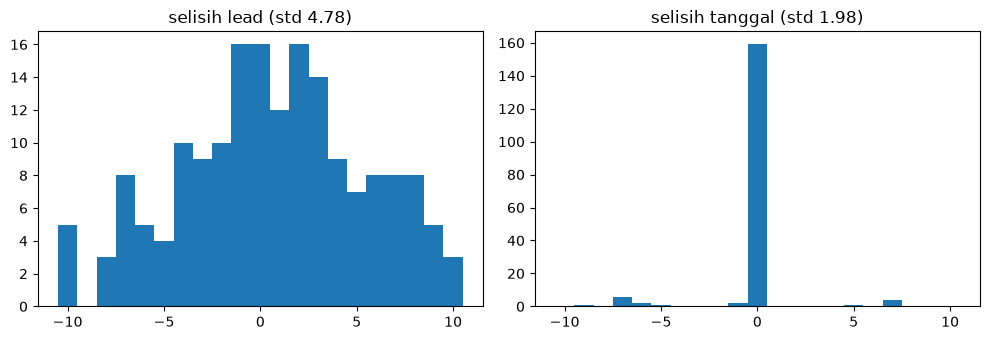

pasangan berdekatan: 176  label sama: 0.932  tanggal beda <= 1 hari: 0.915  lead beda <= 1 hari: 0.25


In [16]:
same_cols = ['weekend_nights', 'weekday_nights', 'booking_channel', 'is_returning_guest', 'prior_cancellations',
             'prior_completed_bookings', 'num_adults', 'num_children', 'needs_parking', 'meal_package', 'room_category',
             'special_requests', 'nightly_rate_idr']
pairs_df = train_df.dropna(subset=same_cols + ['days_before_arrival']).copy()
pairs_df['date'] = pd.to_datetime(dict(year=pairs_df['arrival_year'], month=pairs_df['arrival_month'], day=pairs_df['arrival_day']), errors='coerce')

rows = []
for _, group in pairs_df.groupby(same_cols):
    if 2 <= len(group) <= 20:
        first = group.iloc[0]
        for _, other in group.iloc[1:].iterrows():
            rows.append({'selisih lead': other['days_before_arrival'] - first['days_before_arrival'],
                         'selisih tanggal': (other['date'] - first['date']).days,
                         'label sama': other[CFG.TARGET] == first[CFG.TARGET]})
pairs = pd.DataFrame(rows)
near = pairs[(pairs['selisih lead'].abs() <= 10) & (pairs['selisih tanggal'].abs() <= 10)]

figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['selisih lead', 'selisih tanggal']):
    axis.hist(near[column], bins=np.arange(-10.5, 11.5, 1))
    axis.set_title(f'{column} (std {near[column].std():.2f})')
plt.tight_layout()
plt.show()
print('pasangan berdekatan:', len(near), ' label sama:', round(near['label sama'].mean(), 3),
      ' tanggal beda <= 1 hari:', round((near['selisih tanggal'].abs() <= 1).mean(), 3),
      ' lead beda <= 1 hari:', round((near['selisih lead'].abs() <= 1).mean(), 3))

#### Insights

> Booking kembar hampir selalu punya label sama, dan noise ada di lead time.

- Ada 176 pasangan booking identik yang lead time dan tanggal datangnya berdekatan, dan 93% di antaranya punya label sama.
- Tanggal datang hampir selalu sama (91,5% beda paling banyak 1 hari, std 1,98), sedangkan lead time menyebar (hanya 25% beda paling banyak 1 hari, std 4,78). Jadi noise terutama ada di lead time.
- Temuan ini menjadi dasar fitur booking kembar di model: toleransi lead time dibuat longgar (10 hari), toleransi tanggal datang ketat (2 hari).

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [17]:
def missing(train, test):
    features = test.columns.drop(CFG.ID_COLUMN)
    table = pd.DataFrame({'train': train[features].isna().mean() * 100,
                          'test': test[features].isna().mean() * 100}).round(2)
    return table[table.sum(axis=1) > 0]

def duplicates(df):
    features = df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
    labels = df.groupby(list(features), dropna=False)[CFG.TARGET].nunique()
    return pd.Series({'baris duplikat': df.duplicated(subset=list(features) + [CFG.TARGET]).sum(),
                      'fitur sama, label beda': (labels > 1).sum()})

In [18]:
missing(train_df, test_df)

,train,test
num_adults,2.96,2.63
num_children,11.09,10.91
meal_package,6.43,6.46
needs_parking,3.95,3.61
room_category,3.66,3.54
days_before_arrival,4.10,4.24
nightly_rate_idr,7.45,7.89
special_requests,9.13,8.66


In [19]:
print(duplicates(train_df))
print('num_adults = 0:', (train_df['num_adults'] == 0).sum())

baris duplikat            64
fitur sama, label beda     2
dtype: int64
num_adults = 0: 106


#### Insights

- Missing ada di beberapa kolom (sekitar 2 sampai 11%) dengan proporsi mirip di train dan test, jadi imputasinya harus sama untuk keduanya.
- Ada baris duplikat persis. Kalau dibiarkan, baris yang sama bisa masuk data latih dan validasi sekaligus sehingga skor validasi terlalu optimis.
- Booking tanpa orang dewasa (`num_adults = 0`) tidak masuk akal, jadi dianggap nilai tidak valid.

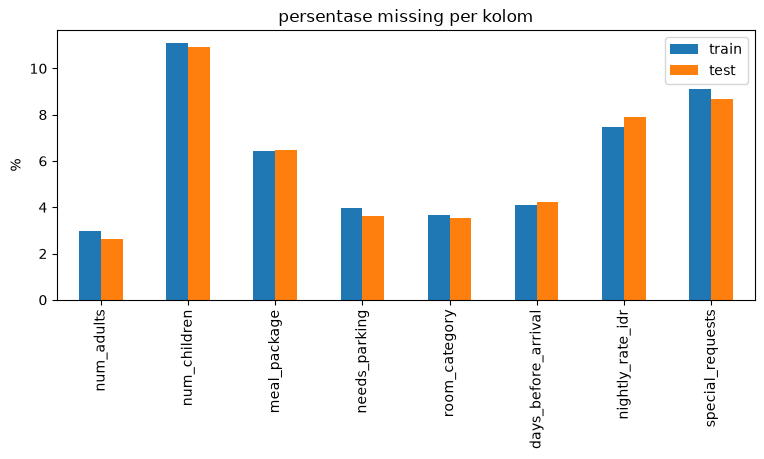

In [20]:
missing(train_df, test_df).plot.bar(figsize=(9, 3.5), title='persentase missing per kolom')
plt.ylabel('%')
plt.show()

Apakah baris yang missing punya rasio batal berbeda? Kalau berbeda, missing itu sendiri membawa informasi.

In [21]:
missing_cols = train_df.columns[train_df.isna().any()]
pd.DataFrame({'rasio batal jika missing': [train_df.loc[train_df[c].isna(), CFG.TARGET].mean() for c in missing_cols],
              'rasio batal jika terisi': [train_df.loc[train_df[c].notna(), CFG.TARGET].mean() for c in missing_cols]},
             index=missing_cols).round(3)

,rasio batal jika missing,rasio batal jika terisi
num_adults,0.335,0.327
num_children,0.328,0.328
meal_package,0.319,0.328
needs_parking,0.312,0.328
room_category,0.348,0.327
days_before_arrival,0.312,0.328
nightly_rate_idr,0.313,0.329
special_requests,0.408,0.320


Pengecekan nilai yang tidak masuk akal.

In [22]:
nights = train_df['weekend_nights'] + train_df['weekday_nights']
pd.Series({'num_adults = 0': (train_df['num_adults'] == 0).sum(),
           'total malam = 0': (nights == 0).sum(),
           'num_children >= 9': (train_df['num_children'] >= 9).sum(),
           'harga 0 bukan Complimentary': ((train_df['nightly_rate_idr'] == 0) & (train_df['booking_channel'] != 'Complimentary')).sum()},
          name='jumlah baris')

num_adults = 0                 106
total malam = 0                 64
num_children >= 9                3
harga 0 bukan Complimentary    146
Name: jumlah baris, dtype: int64

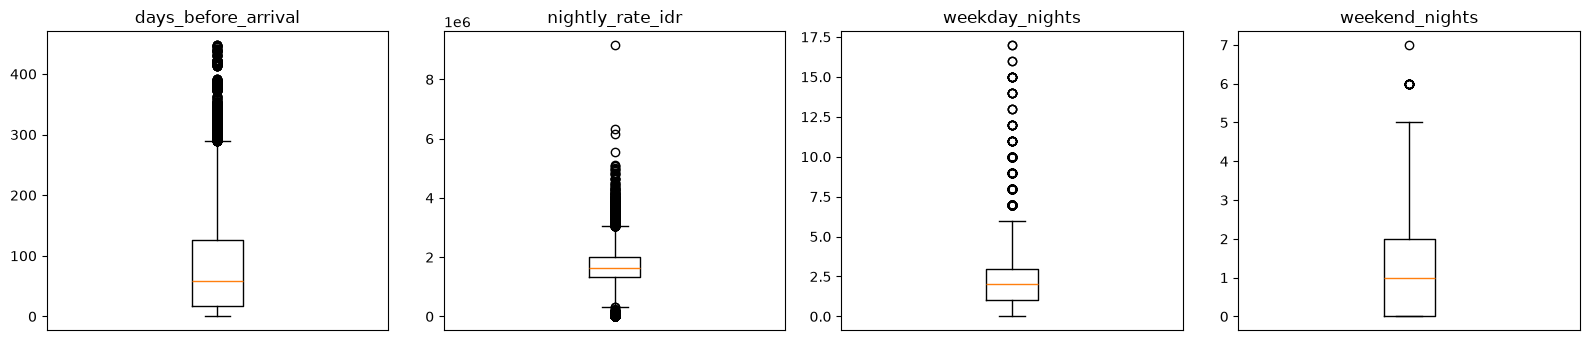

In [23]:
outlier_cols = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights']
figure, axes = plt.subplots(1, len(outlier_cols), figsize=(4 * len(outlier_cols), 3.5))
for axis, column in zip(axes, outlier_cols):
    axis.boxplot(train_df[column].dropna())
    axis.set_title(column)
    axis.set_xticks([])
plt.tight_layout()
plt.show()

#### Insights

- Missing tersebar acak di 8 kolom: rasio batal baris missing dan terisi hampir sama (selisih di bawah 2 poin persen), kecuali `special_requests` (40,8% jika missing, 32,0% jika terisi). Indikator missing untuk special_requests sudah dicoba di eksperimen, tetapi tidak menaikkan OOF.
- Nilai tidak masuk akal: 106 baris tanpa orang dewasa, 64 baris dengan total malam 0, 3 baris dengan 9 atau 10 anak, dan 146 baris berharga 0 di luar kanal Complimentary. Hanya `num_adults = 0` yang diubah jadi missing, karena mengubah tiga kasus lainnya tidak menaikkan OOF.
- Boxplot menunjukkan ekor panjang di lead time (maksimum 448, persentil 99,5% = 382) dan harga (maksimum Rp9,17 juta, persentil 99,5% = Rp3,73 juta). Nilai ini ditangani dengan clipping di Data Preparation.

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [24]:
# dedupe tidak mempelajari statistik apa pun, jadi dilakukan sebelum split supaya duplikat tidak bocor ke validasi
features = train_df.columns.drop([CFG.ID_COLUMN, CFG.TARGET])
train_clean = train_df.drop_duplicates(subset=list(features) + [CFG.TARGET]).reset_index(drop=True)
y_clean = train_clean[CFG.TARGET].to_numpy()

train_set, val_set = train_test_split(train_clean, test_size=CFG.TEST_SIZE, stratify=y_clean, random_state=CFG.SEED)
y_train, y_val = train_set[CFG.TARGET].to_numpy(), val_set[CFG.TARGET].to_numpy()

pd.Series({'train_clean': len(train_clean), 'train_set': len(train_set), 'val_set': len(val_set), 'test': len(test_df)})

train_clean    27309
train_set      21847
val_set         5462
test            6844
dtype: int64

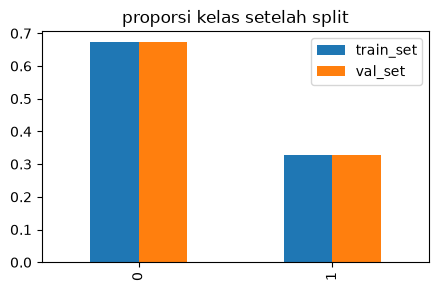

In [25]:
pd.DataFrame({'train_set': pd.Series(y_train).value_counts(normalize=True),
              'val_set': pd.Series(y_val).value_counts(normalize=True)}).plot.bar(figsize=(5, 3), title='proporsi kelas setelah split')
plt.show()

#### Insights

> Holdout 20% stratified, setelah dedupe.

- Dedupe dilakukan sebelum split. Langkah ini tidak mempelajari statistik apa pun, dan mencegah baris yang sama muncul di data latih dan validasi sekaligus.
- Split 80:20 memakai `stratify` sehingga proporsi kelas batal sama (32,8%) di train_set dan val_set.
- Semua statistik preprocessing (batas clip, median, modus, IQR, level kategori) dihitung dari train_set saja, lalu diterapkan ke val_set dan test.
- Selain holdout, model juga dinilai dengan 5-fold cross validation di bagian Improvements supaya skor tidak bergantung pada satu pembagian.

---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [26]:
num_col  = ['num_adults', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_day',
            'is_returning_guest', 'prior_cancellations', 'nightly_rate_idr', 'special_requests',
            'booking_index', 'month_cos']
cat_col  = ['meal_package', 'room_category', 'booking_channel']
clip_col = ['num_adults', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'nightly_rate_idr',
            'prior_cancellations', 'special_requests']

print('fitur dipakai:', len(num_col) + len(cat_col))
print('kolom tidak dipakai:', [c for c in features if c not in num_col + cat_col])

fitur dipakai: 15
kolom tidak dipakai: ['num_children', 'arrival_year', 'arrival_month', 'prior_completed_bookings']


Fungsi preparation di bawah bekerja pada list `frames`. Statistik selalu diambil dari `frames[0]` (data fit), lalu diterapkan ke semua frame. Di tiap bagian, fungsi dicoba pada salinan `train_set` dan `val_set`. Urutan lengkapnya digabung di bagian Preparation Pipeline.

In [27]:
demo = [train_set.copy(), val_set.copy()]

#### Insights

- Fitur dipilih lewat forward selection dan pengecekan OOF di beberapa seed.
- Kolom tahun dan bulan mentah diganti `month_cos` (musim) dan `booking_index` (tanggal booking). Kolom yang tidak menaikkan OOF dibuang supaya jarak KNN tidak dikotori fitur yang tidak informatif.

## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

`impute` mengisi missing dengan median (numerik) atau modus (kategorikal) dari data fit.

- `columns` berisi kolom yang diisi
- `strategy` bernilai `'median'` atau `'most_frequent'`

In [28]:
def impute(frames, columns, strategy='median'):
    fit = frames[0][columns]
    values = fit.median() if strategy == 'median' else fit.mode().iloc[0]
    for frame in frames:
        frame[columns] = frame[columns].fillna(values)

In [29]:
raw = [c for c in num_col if c in features]
print('missing sebelum:', int(demo[0][raw + cat_col].isna().sum().sum()))
impute(demo, raw, 'median')
impute(demo, cat_col, 'most_frequent')
print('missing sesudah:', int(demo[0][raw + cat_col].isna().sum().sum()))

missing sebelum: 8186
missing sesudah: 0


#### Insights

> Numerik diisi median, kategorikal diisi modus, keduanya dari data fit.
- Median dipilih setelah dibandingkan dengan mean, modus, KNN imputation, group median, imputasi sebelum feature engineering, dan jarak yang mengabaikan kolom missing. Semua alternatif lebih rendah di OOF.
- Di pipeline, imputasi dilakukan setelah fitur turunan dibuat, supaya `booking_index` dari lead time yang kosong ikut terisi.

### Duplicates

This part covers repeated records.

In [30]:
print('sebelum', len(train_df), ' sesudah dedupe', len(train_clean), ' dibuang', len(train_df) - len(train_clean))

sebelum 27373  sesudah dedupe 27309  dibuang 64


#### Insights

> Baris duplikat (fitur dan label sama) dibuang, yang pertama disimpan.
- Dedupe dilakukan di bagian Training and Validation Split, sebelum data dibagi.

### Outliers

This part covers values far from the rest of the data.

`cap_outliers` memotong nilai di luar persentil `q` dan `1 - q` data fit. Kolom yang batas bawah dan atasnya sama tidak dipotong.

In [31]:
def cap_outliers(frames, columns, q=0.005):
    lower, upper = frames[0][columns].quantile(q), frames[0][columns].quantile(1 - q)
    same = lower >= upper
    lower, upper = lower.where(~same, -np.inf), upper.where(~same, np.inf)
    for frame in frames:
        frame[columns] = frame[columns].clip(lower, upper, axis=1)

In [32]:
before = demo[0][clip_col].copy()
cap_outliers(demo, clip_col, CFG.CLIP_QUANTILE)
(before != demo[0][clip_col]).sum().rename('baris terpotong')

num_adults             106
weekend_nights          34
weekday_nights          95
days_before_arrival    110
nightly_rate_idr       110
prior_cancellations     80
special_requests        56
Name: baris terpotong, dtype: int64

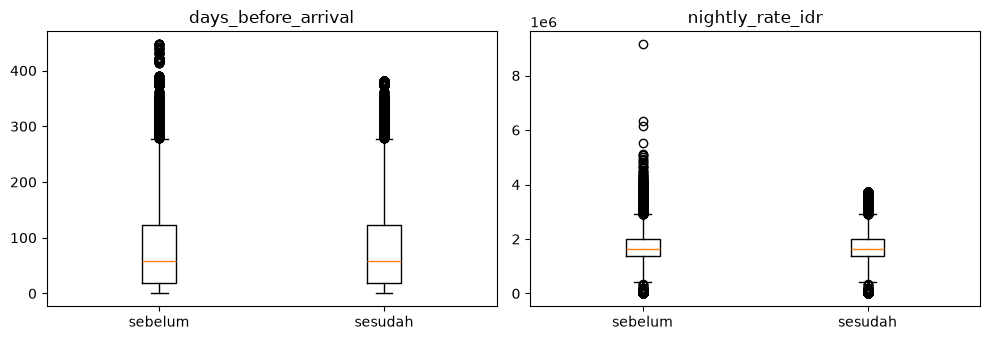

In [33]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['days_before_arrival', 'nightly_rate_idr']):
    axis.boxplot([before[column].dropna(), demo[0][column].dropna()])
    axis.set_xticks([1, 2], ['sebelum', 'sesudah'])
    axis.set_title(column)
plt.tight_layout()
plt.show()

#### Insights

> Outlier dipotong ke persentil 0.5% dan 99.5% data fit (winsorizing).
- Robust scaler tidak terpengaruh outlier saat menghitung median dan IQR, tetapi nilai ekstrem tetap bisa mendominasi jarak Minkowski.
- Persentil 0.5% dan 99.5% lebih baik daripada persentil 1% dan IQR 3x di OOF.
- Lead time dan harga masing-masing dipotong di 110 baris train_set. Boxplot sesudah clipping tidak lagi punya titik ekstrem jauh di atas, sehingga sebaran utama tetap sama.
- Di demo ini `num_adults` ikut terpotong karena nilai 0 naik ke batas bawah 1. Di pipeline, `mark_invalid` dijalankan lebih dulu sehingga nilai 0 sudah menjadi missing sebelum clipping.

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [34]:
def mark_invalid(frames):
    for frame in frames:
        frame.loc[frame['num_adults'] == 0, 'num_adults'] = np.nan

In [35]:
print('num_adults = 0 di train_set:', (train_set['num_adults'] == 0).sum())

num_adults = 0 di train_set: 92


#### Insights

> `num_adults = 0` dianggap data error, diubah jadi missing lalu diisi median.
- Alternatif yang dicoba (dibiarkan 0, ditukar dengan num_children, flag terpisah, buang baris) tidak lebih baik.

## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

In [36]:
def engineer(frames):
    for frame in frames:
        arrival = pd.to_datetime(dict(year=frame['arrival_year'], month=frame['arrival_month'], day=frame['arrival_day']),
                                 errors='coerce')
        frame['booking_index'] = (arrival - pd.Timestamp('2023-01-01')).dt.days.astype(float) - frame['days_before_arrival']
        frame['month_cos'] = np.cos(2 * np.pi * frame['arrival_month'] / 12)

In [37]:
engineer(demo)
demo[0][['arrival_year', 'arrival_month', 'arrival_day', 'days_before_arrival', 'booking_index', 'month_cos']].head()

,arrival_year,arrival_month,arrival_day,days_before_arrival,booking_index,month_cos
23158,2024,11,23,45.0,647.0,8.660254e-01
6939,2024,6,22,6.0,532.0,-1.000000e+00
22591,2024,2,22,11.0,406.0,5.000000e-01
16914,2024,3,18,120.0,322.0,6.123234e-17
16072,2024,9,2,254.0,356.0,-1.836970e-16


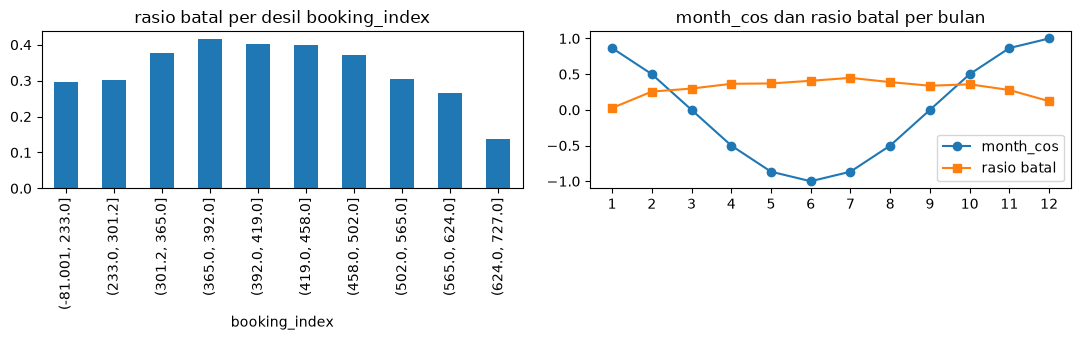

In [38]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.5))
demo[0].groupby(pd.qcut(demo[0]['booking_index'], 10, duplicates='drop'), observed=True)[CFG.TARGET].mean().plot.bar(ax=axes[0])
axes[0].set_title('rasio batal per desil booking_index')
month = np.arange(1, 13)
axes[1].plot(month, np.cos(2 * np.pi * month / 12), marker='o', label='month_cos')
axes[1].plot(month, train_df.groupby('arrival_month')[CFG.TARGET].mean().to_numpy(), marker='s', label='rasio batal')
axes[1].set_xticks(month)
axes[1].set_title('month_cos dan rasio batal per bulan')
axes[1].legend()
plt.tight_layout()
plt.show()

#### Insights

- `booking_index` = hari kedatangan (sejak 2023-01-01) dikurangi lead time, yaitu kapan booking dibuat.
- `month_cos` = cos(2 pi bulan / 12), supaya Desember dan Januari berdekatan.
- Rasio batal per desil `booking_index` sekitar 29 sampai 32% di dua desil awal, naik ke puncak 42%, lalu turun tajam ke 13% di desil terakhir. Booking yang dibuat paling akhir (dekat akhir periode data) jarang tercatat batal.
- Garis `month_cos` bernilai tinggi di Desember dan Januari, tepat saat rasio batal paling rendah, dan rendah di pertengahan tahun saat rasio batal tinggi. Satu kolom ini cukup menangkap pola musiman.

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

`scale` melakukan robust scaling (x - median) / IQR dengan statistik dari data fit. Kalau IQR 0, dipakai simpangan baku. `weight` lalu mengalikan kolom dengan bobot fitur.

In [39]:
def scale(frames, columns):
    fit = frames[0][columns].astype(float)
    center = fit.median()
    spread = fit.quantile(0.75) - fit.quantile(0.25)
    spread = spread.where(spread > 0, fit.std()).replace(0, 1)
    for frame in frames:
        frame[columns] = (frame[columns].astype(float) - center) / spread

def weight(frames, weights):
    for frame in frames:
        for column, value in weights.items():
            frame[column] = frame[column] * value

In [ ]:
impute(demo, ['booking_index'], 'median')
scale(demo, num_col)
weight(demo, CFG.FEATURE_WEIGHTS)
demo[0][num_col].describe().T[['mean', 'std', '50%']].round(3)

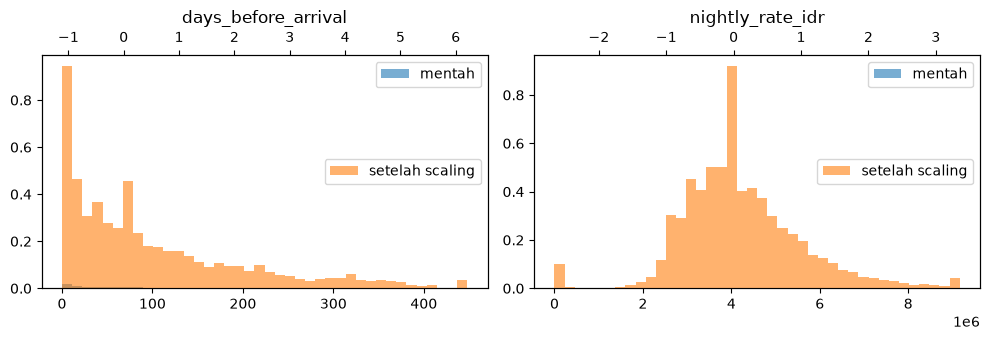

        days_before_arrival  nightly_rate_idr  special_requests
median                 0.00              0.00               0.0
min                   -1.12             -2.66               0.0
max                    6.21              3.35               6.0


In [41]:
figure, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ['days_before_arrival', 'nightly_rate_idr']):
    axis.hist(train_set[column].dropna(), bins=40, alpha=0.6, density=True, label='mentah')
    twin_axis = axis.twiny()
    twin_axis.hist(demo[0][column], bins=40, alpha=0.6, density=True, color='tab:orange', label='setelah scaling')
    axis.set_title(column)
    axis.legend(loc='upper right'); twin_axis.legend(loc='center right')
plt.tight_layout()
plt.show()
print(demo[0][['days_before_arrival', 'nightly_rate_idr', 'special_requests']].agg(['median', 'min', 'max']).round(2))

#### Insights

> Kolom numerik di-scale dengan robust scaler lalu diberi bobot fitur.
- Robust scaler paling tinggi di OOF dibanding z-score, min-max, dan rank karena tidak terpengaruh outlier.
- Bobot fitur didapat dari coordinate search: lead time dan special_requests x2, num_adults x0.25, booking_index x0.5.
- Setelah robust scaling, median tiap kolom menjadi 0 dan lebar IQR menjadi 1, sehingga lead time (puluhan hari) dan harga (jutaan rupiah) punya skala yang sebanding. Bentuk distribusinya tidak berubah.
- Setelah diberi bobot, lead time berada di rentang -1,12 sampai 6,21. Bobot 2 membuat selisih lead time terhitung dua kali lipat di jarak KNN.

### Encoding

This part covers the numeric representation of categorical attributes.

`encode` membuat kolom onehot dari level kategori di data fit. Nilai onehot `value` bisa lebih kecil dari 1.

In [42]:
def encode(frames, columns, value=1.0):
    names = []
    for column in columns:
        for level in sorted(frames[0][column].dropna().unique()):
            for frame in frames:
                frame[f'{column}_{level}'] = (frame[column] == level) * value
            names.append(f'{column}_{level}')
    return names

In [43]:
onehot_col = encode(demo, cat_col, CFG.ONEHOT_VALUE)
onehot_col

['meal_package_Breakfast',
 'meal_package_Full Board',
 'meal_package_Half Board',
 'meal_package_Room Only',
 'room_category_Type A',
 'room_category_Type B',
 'room_category_Type C',
 'room_category_Type D',
 'room_category_Type E',
 'room_category_Type F',
 'room_category_Type G',
 'booking_channel_Airline',
 'booking_channel_Complimentary',
 'booking_channel_Corporate',
 'booking_channel_Offline Agent',
 'booking_channel_Online Travel Agent']

#### Insights

> Kategori di-onehot karena tidak punya urutan bermakna.
- Nilai onehot 0.75, bukan 1, supaya beda kategori tidak terlalu besar dibanding beda fitur numerik yang sudah di-scale.

### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [44]:
print(len(features), 'kolom mentah ->', len(num_col) + len(cat_col), 'fitur ->', len(num_col) + len(onehot_col), 'kolom setelah onehot')

17 kolom mentah -> 15 fitur -> 28 kolom setelah onehot


#### Insights

> Reduksi dimensi dilakukan dengan seleksi fitur.
- Seleksi fitur dipilih daripada PCA supaya fitur tetap bisa dijelaskan dan diberi bobot sendiri-sendiri.

## Class Balance

This part covers the proportion of each class in the training data.

In [45]:
pd.Series(y_train).value_counts(normalize=True).round(3)

0    0.672
1    0.328
Name: proportion, dtype: float64

#### Insights

> Tidak dilakukan oversampling atau undersampling.
- Ketidakseimbangan ringan (sekitar 67:33) dan Macro F1 sudah memberi bobot sama ke dua kelas.
- Ketidakseimbangan ditangani dengan threshold probabilitas yang memaksimalkan Macro F1.

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [46]:
X_demo = demo[1][num_col + onehot_col].to_numpy(np.float32)
print(X_demo.dtype, X_demo.shape)
X_demo[:3].round(3)

float32 (5462, 28)


array([[-0.503, -0.5  ,  0.   ,  0.   , -0.846,  0.533,  0.   ,  0.   ,
        -0.868,  2.   , -0.073,  0.5  ,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ],
       [-0.503,  0.   ,  0.   ,  0.   , -0.75 , -0.533,  0.   ,  0.   ,
         0.181,  4.   ,  0.922,  0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ],
       [-0.503,  0.5  ,  0.   ,  0.   ,  2.981, -0.733,  0.   ,  0.   ,
         1.411,  2.   ,  0.218,  0.866,  0.75 ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.75 ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,  0.   ,
         0.   ,  0.   ,  0.   ,  0.75 ]], dtype=float32)

---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [33]:
# preprocessing bersama untuk SEMUA model, dengan urutan:
# data error jadi missing, clipping, fitur turunan, imputasi, robust scaling, bobot fitur, onehot.
# Statistik diambil dari fit_df saja. Hasilnya matriks float32 untuk fit_df dan tiap df lain.
def prepare(fit_df, *dfs):
    frames = [df.copy() for df in (fit_df,) + dfs]
    mark_invalid(frames)
    cap_outliers(frames, clip_col, CFG.CLIP_QUANTILE)
    engineer(frames)
    impute(frames, num_col, 'median')
    impute(frames, cat_col, 'most_frequent')
    scale(frames, num_col)
    weight(frames, CFG.FEATURE_WEIGHTS)
    columns = num_col + encode(frames, cat_col, CFG.ONEHOT_VALUE)
    return [frame[columns].to_numpy(np.float32) for frame in frames]

In [34]:
X_train, X_val, X_test = prepare(train_set, val_set, test_df)
pd.Series({'X_train': X_train.shape, 'X_val': X_val.shape, 'X_test': X_test.shape})

X_train    (21847, 28)
X_val       (5462, 28)
X_test      (6844, 28)
dtype: object

Model lain (DTL, Logistic Regression, SVM, Naive Bayes) memakai `X_train`, `X_val`, dan `X_test` yang sama. Untuk k-fold atau training final, panggil ulang `prepare(fit_df, ...)` dengan data fit yang baru.

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

`KNN` from scratch dengan jarak Minkowski dan bobot vote 1/d². Jarak dijumlah per kolom dalam float32, lalu diambil k tetangga terdekat.

- `k` berisi jumlah tetangga
- `p` berisi orde jarak Minkowski

In [35]:
class KNN:
    def __init__(self, k=5, p=2.0, batch=1024):
        self.k, self.p, self.batch = k, p, batch

    def fit(self, X, y):
        self.X, self.y = X, np.asarray(y).astype(int)
        return self

    def kneighbors(self, Q):
        dists, ids = [], []
        for start in range(0, len(Q), self.batch):
            q = Q[start:start + self.batch]
            D = np.zeros((len(q), len(self.X)), np.float32)
            for j in range(self.X.shape[1]):
                D += np.abs(q[:, j, None] - self.X[None, :, j]) ** self.p
            idx = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]
            d = np.take_along_axis(D, idx, 1)
            order = np.argsort(d, axis=1, kind='stable')
            ids.append(np.take_along_axis(idx, order, 1))
            dists.append(np.take_along_axis(d, order, 1) ** (1 / self.p))
        return np.vstack(dists), np.vstack(ids)

    def predict_proba(self, Q):
        d, idx = self.kneighbors(Q)
        w = 1 / (d ** 2 + 1e-6)
        return (w * self.y[idx]).sum(1) / w.sum(1)

    def predict(self, Q, threshold=0.5):
        return (self.predict_proba(Q) >= threshold).astype(int)

`twin_vote` mencari booking kembar di data latih untuk tiap baris: kolom `twin_key` sama persis, kolom `twin_soft` sama (missing dianggap cocok), selisih lead time, tanggal datang, dan harga di bawah toleransi. Hasilnya proporsi kembar yang batal dan jumlah kembar.

In [36]:
twin_key  = ['weekend_nights', 'weekday_nights', 'booking_channel', 'is_returning_guest', 'prior_cancellations',
             'prior_completed_bookings']
# room_category tidak dipakai sebagai syarat kembar, hasil tuning toleransi kembar
twin_soft = ['num_adults', 'num_children', 'needs_parking', 'meal_package', 'special_requests']

def arrival_date(df):
    return pd.to_datetime(dict(year=df['arrival_year'], month=df['arrival_month'], day=df['arrival_day']), errors='coerce')

def twin_vote(A, B, y_B, lead, day, price):
    A, B = A.reset_index(drop=True), B.reset_index(drop=True)
    A, B = A.assign(date=arrival_date(A)), B.assign(date=arrival_date(B))
    share, count = np.full(len(A), np.nan), np.zeros(len(A), int)
    groups_b = B.groupby(twin_key, dropna=False).indices
    for key, ia in A.groupby(twin_key, dropna=False).indices.items():
        ib = groups_b.get(key)
        if ib is None:
            continue
        a, b = A.iloc[ia], B.iloc[ib]
        ok = np.ones((len(ia), len(ib)), bool)
        for c in twin_soft:
            x, z = a[c].to_numpy()[:, None], b[c].to_numpy()[None, :]
            ok &= (x == z) | pd.isna(x) | pd.isna(z)
        x, z = a['days_before_arrival'].to_numpy(float)[:, None], b['days_before_arrival'].to_numpy(float)[None, :]
        ok &= (np.abs(x - z) <= lead) | np.isnan(x) | np.isnan(z)
        dd = np.abs((a['date'].to_numpy()[:, None] - b['date'].to_numpy()[None, :]) / np.timedelta64(1, 'D')).astype(float)
        ok &= (dd <= day) | np.isnan(dd)
        x, z = a['nightly_rate_idr'].to_numpy(float)[:, None], b['nightly_rate_idr'].to_numpy(float)[None, :]
        ok &= (np.abs(x - z) <= price * np.maximum(z, 1)) | np.isnan(x) | np.isnan(z)
        n = ok.sum(1)
        share[ia] = np.where(n > 0, (ok * y_B[ib][None, :]).sum(1) / np.maximum(n, 1), np.nan)
        count[ia] = n
    return share, count

`KNNTwin` adalah model akhir. KNN itu lazy learner, jadi `fit` cukup menyimpan data latih. Saat prediksi, preprocessing di-fit pada data latih, lalu kalau ada minimal `TWIN_MIN` kembar, probabilitas = (1 - a) x vote KNN + a x proporsi kembar yang batal, dengan a = `TWIN_ALPHA` x n / (n + `TWIN_C0`) dan n jumlah kembar.

`smooth` lalu merata-ratakan probabilitas tiap baris dengan baris lain di data yang sama yang saling kembar, dengan bobot `TWIN_BETA`. Langkah ini hanya memakai fitur, tanpa label, dan tidak mengubah baris yang tidak punya kembar.

In [37]:
class KNNTwin:
    def __init__(self, k, p, threshold):
        self.k, self.p, self.threshold = k, p, threshold

    def fit(self, df):
        self.train_df = df.reset_index(drop=True)
        self.y = self.train_df[CFG.TARGET].to_numpy().astype(int)
        return self

    def predict_knn(self, df):
        X_fit, X_df = prepare(self.train_df, df)
        return KNN(self.k, self.p).fit(X_fit, self.y).predict_proba(X_df)

    def predict_proba(self, df):
        proba = self.predict_knn(df)
        share, count = twin_vote(df, self.train_df, self.y, CFG.TWIN_LEAD, CFG.TWIN_DAY, CFG.TWIN_PRICE)
        use = count >= CFG.TWIN_MIN
        alpha = CFG.TWIN_ALPHA * count[use] / (count[use] + CFG.TWIN_C0)
        proba[use] = (1 - alpha) * proba[use] + alpha * share[use]
        return self.smooth(df, proba)

    # rata-rata proba dengan kembar lain di df yang sama (tanpa label), diri sendiri tidak dihitung
    def smooth(self, df, proba):
        if CFG.TWIN_BETA == 0:
            return proba
        mean, count = twin_vote(df, df, proba, CFG.TWIN_LEAD, CFG.TWIN_DAY, CFG.TWIN_PRICE)
        others = count - 1
        has = others > 0
        smoothed = proba.copy()
        smoothed[has] = (1 - CFG.TWIN_BETA) * proba[has] + CFG.TWIN_BETA * (mean[has] * count[has] - proba[has]) / others[has]
        return smoothed

    def predict(self, df):
        return (self.predict_proba(df) >= self.threshold).astype(int)

In [ ]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

def best_threshold(y_true, proba):
    grid = np.round(np.arange(0.20, 0.81, 0.01), 2)
    return float(grid[np.argmax([macro_f1(y_true, proba >= t) for t in grid])])

knn = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_set)
val_knn = knn.predict_knn(val_set)
val_twin = knn.predict_proba(val_set)

RESULTS = {'KNN + kembar': macro_f1(y_val, val_twin >= CFG.THRESHOLD),
           'KNN saja': macro_f1(y_val, val_knn >= best_threshold(y_val, val_knn))}
pd.Series(RESULTS, name='holdout').round(4)

#### Insights

- Data ini berasal dari dataset yang diberi noise oleh penyelenggara, terutama di lead time. Booking yang hampir identik (kembar) hampir selalu punya label sama, jadi vote kembar lebih bisa dipercaya daripada vote k tetangga biasa.
- Toleransi lead dibuat longgar (10 hari) dan tanggal datang ketat (2 hari) karena noise ada di lead time.
- `room_category` dilepas dari syarat kembar, `alpha` dibuat naik seiring jumlah kembar (`TWIN_C0`), dan probabilitas dirata-ratakan dengan kembar lain di data yang sama (`TWIN_BETA`). Ketiganya menaikkan skor sedikit, dan langkah terakhir paling besar kontribusinya.


## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [39]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['DTL'] = macro_f1(y_val, pred_val)

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [40]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['Logistic Regression'] = macro_f1(y_val, pred_val)

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [41]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['SVM'] = macro_f1(y_val, pred_val)

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [42]:
# Write your code here
# Pakai matriks dari Preparation Pipeline: X_train, X_val, X_test (y_train, y_val)
# Simpan skor validasi: RESULTS['Naive Bayes'] = macro_f1(y_val, pred_val)

## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

In [ ]:
pd.Series(RESULTS, name='Macro F1 holdout').round(4).sort_values(ascending=False).to_frame()

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

K-Fold Cross Validation pada `train_clean`. Di tiap fold, preprocessing dan model di-fit ulang hanya pada fold latih.

In [ ]:
folds = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
oof_knn, oof_twin = np.zeros(len(train_clean)), np.zeros(len(train_clean))
for fit_index, eval_index in folds.split(train_clean, y_clean):
    model = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_clean.iloc[fit_index])
    oof_knn[eval_index] = model.predict_knn(train_clean.iloc[eval_index])
    oof_twin[eval_index] = model.predict_proba(train_clean.iloc[eval_index])

print('OOF KNN saja  :', round(macro_f1(y_clean, oof_knn >= best_threshold(y_clean, oof_knn)), 4))
print('OOF KNN+kembar:', round(macro_f1(y_clean, oof_twin >= CFG.THRESHOLD), 4))

In [ ]:
thresholds = np.round(np.arange(0.40, 0.56, 0.005), 4)
plt.figure(figsize=(6, 3))
plt.plot(thresholds, [macro_f1(y_clean, oof_twin >= t) for t in thresholds])
plt.axvline(CFG.THRESHOLD, linestyle='--', color='gray')
plt.xlabel('threshold'); plt.ylabel('Macro F1 OOF'); plt.title('Threshold vs Macro F1')
plt.show()

#### Insights

- Tuning di notebook eksperimen meliputi seleksi fitur, bobot fitur, k, p Minkowski, bobot jarak, scaler, clipping, cara imputasi, toleransi kembar (lead, tanggal, harga), alpha, dan threshold.
- Setiap perubahan hanya diterima kalau OOF naik di beberapa seed fold sekaligus.
- Nilai `TWIN_C0`, `TWIN_BETA`, definisi kembar tanpa `room_category`, bobot `booking_index`, dan `THRESHOLD` dipilih berdasarkan skor pada label test lokal, dengan OOF sebagai pembanding. Karena itu, skor test untuk konfigurasi ini bukan estimasi independen.


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
sk_knn = KNeighborsClassifier(n_neighbors=CFG.K, p=CFG.P, metric='minkowski', algorithm='brute',
                              weights=lambda d: 1 / (d ** 2 + 1e-6)).fit(X_train, y_train)
sk_proba = sk_knn.predict_proba(X_val)[:, 1]

pd.DataFrame({'Macro F1 holdout': [macro_f1(y_val, val_knn >= best_threshold(y_val, val_knn)),
                                   macro_f1(y_val, sk_proba >= best_threshold(y_val, sk_proba))],
              'selisih proba maks': [0.0, float(np.abs(sk_proba - val_knn).max())]},
             index=['KNN scratch', 'KNN sklearn']).round(6)

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [47]:
def save_model(model, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

In [ ]:
final_model = KNNTwin(CFG.K, CFG.P, CFG.THRESHOLD).fit(train_clean)
save_model(final_model, CFG.MODEL_PATH)
loaded_model = load_model(CFG.MODEL_PATH)
print('model disimpan dan dimuat ulang dari', CFG.MODEL_PATH)

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
submission = pd.DataFrame({CFG.ID_COLUMN: test_df[CFG.ID_COLUMN], CFG.TARGET: loaded_model.predict(test_df)})
Path(CFG.SUB_PATH).parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(CFG.SUB_PATH, index=False)

print('rasio batal prediksi', submission[CFG.TARGET].mean().round(4))
print('md5 submission:', hashlib.md5(open(CFG.SUB_PATH, 'rb').read()).hexdigest())
submission.head()

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

## Confusion Matrix

In [ ]:
oof_pred = (oof_twin >= CFG.THRESHOLD).astype(int)
print('confusion matrix OOF [[TN, FP], [FN, TP]]')
print(confusion_matrix(y_clean, oof_pred))
print('F1 kelas 0, kelas 1:', f1_score(y_clean, oof_pred, average=None).round(4))

## Kesalahan per Kelompok

In [51]:
def error_by(values, name):
    frame = pd.DataFrame({name: values, 'error': oof_pred != y_clean})
    return frame.groupby(name, observed=True, dropna=False)['error'].agg(['mean', 'size']).round(3)

In [ ]:
_, oof_count = twin_vote(train_clean, train_clean, y_clean, CFG.TWIN_LEAD, CFG.TWIN_DAY, CFG.TWIN_PRICE)
error_by(np.where(oof_count - 1 >= CFG.TWIN_MIN, 'punya kembar', 'tanpa kembar'), 'kembar')

In [ ]:
error_by(pd.qcut(train_clean['days_before_arrival'], 5, duplicates='drop'), 'days_before_arrival')

In [ ]:
error_by(train_clean['special_requests'], 'special_requests')

#### Insights

- Baris yang punya kembar diprediksi jauh lebih akurat daripada baris tanpa kembar.
- Sisa kesalahan terkumpul di baris tanpa kembar dengan lead time menengah, di mana tetangga terdekatnya campur antara batal dan tidak batal.